Add you import statements in the below code block. Please make sure to import Precode.

In [1]:
# import code here
from precode import *
import numpy
import pandas as pd

data = np.load('AllSamples.npy')

Below cell contains starter code to generate the initial centers. 

* Please do not change anything apart from the student ID.

* The initial centers will be in a dictionary with keys being 'k' and value being the centers.


In [2]:
initial_centers = {}

for k in range(2, 11):
    centers = initial_S1("4853", k)  # please replace 0111 with your last four digit of your ID
    initial_centers[k] = centers

Print the last 4 digits of your student id as string in the cell below. Please make sure to only have one print statement in the cell below.

In [3]:
### TEST FUNCTION: test_student_id
# DO NOT REMOVE THE ABOVE LINE
print('4853')

4853


Add your code for computing the kMeans final centroids and loss functions in the code block below.

In [4]:
# Implement K-means using the Strategy 1 initial centers.
def run_kmeans(data, initial_centroids):
    centroids = initial_centroids.copy()
    k = len(centroids)

    while True:
        # Calculate the squared Euclidean distance from every point
        # to every centroid.
        distances = np.sum(
            (data[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2,
            axis=2
        )

        # Assign each point to its nearest centroid.
        labels = np.argmin(distances, axis=1)

        # Recompute each centroid from the points assigned to it.
        new_centroids = []

        for cluster_index in range(k):
            cluster_points = data[labels == cluster_index]

            # An empty cluster usually indicates an upstream problem.
            if len(cluster_points) == 0:
                raise ValueError(
                    f"Empty cluster encountered for cluster {cluster_index}"
                )

            new_centroids.append(
                np.mean(cluster_points, axis=0)
            )

        new_centroids = np.array(new_centroids)

        # Stop only when the centroids are exactly unchanged.
        if np.array_equal(centroids, new_centroids):
            centroids = new_centroids
            break

        centroids = new_centroids

    # Recompute assignments using the final centroids.
    distances = np.sum(
        (data[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2,
        axis=2
    )
    labels = np.argmin(distances, axis=1)

    # Compute the K-means objective function:
    # sum of squared distances to each point's assigned centroid.
    loss = np.sum(
        (data - centroids[labels]) ** 2
    )

    return centroids, labels, float(loss)


# Store the final results for k = 2 through 10.
final_centroids = {}
final_labels = {}
losses = {}

for k in range(2, 11):
    centroids, labels, loss = run_kmeans(
        data,
        initial_centers[k]
    )

    final_centroids[k] = centroids
    final_labels[k] = labels
    losses[k] = loss

Please use the following cell to print all the final centeriods for k in the range of 2 to 10, both inclusive.

**Notes:**
* The centeriods should have the following format: `[[x1,y1],[x2,y2],[x3,y3]][[x1,y1],[x2,y2],[x3,y3]]`
* The order of the centeriod does not matter but do NOT change the order for `x` and `y` coordinate.
* Please print the centroids from k=2 to k=10 in order and each on a new line.
* Do not print anything else in the code cell below.

**Output format:**

[[x1, y1], [x2, y2]]

[[x1, y1], [x2, y2], [x3, y3]]

.

.

.

[[x1,y1], [x2,y2].....[x9,y9]]

In [5]:
### TEST FUNCTION: test_question1
# DO NOT REMOVE THE ABOVE LINE

print(final_centroids[2].tolist())
print(final_centroids[3].tolist())
print(final_centroids[4].tolist())
print(final_centroids[5].tolist())
print(final_centroids[6].tolist())
print(final_centroids[7].tolist())
print(final_centroids[8].tolist())
print(final_centroids[9].tolist())
print(final_centroids[10].tolist())

[[6.8071367414942845, 5.401124256878568], [3.0168234306748127, 4.477419275898857]]
[[5.555241823602507, 2.1898095818920966], [6.497249620849709, 7.522972929895171], [2.6194686848974693, 5.965194768533931]]
[[3.1693274926251656, 6.88713892447105], [6.856583330228901, 7.661434199806484], [3.2125746077046626, 2.496580865799525], [7.252626831256577, 2.4001582635520533]]
[[3.91512030145731, 4.0416668866073175], [2.8143219511349615, 7.0809648305567805], [2.9587703023677445, 1.432764367064417], [7.414192434680615, 2.3216911383868664], [6.719429398419655, 7.743329308428545]]
[[3.1757786997757065, 7.156076116526353], [7.528740374493046, 8.555743022813592], [6.078733050391577, 5.869936972601599], [4.818330576085663, 3.69502320071854], [7.556167822397726, 2.235167959857534], [2.681986334188929, 2.094615867800809]]
[[2.681986334188929, 2.094615867800809], [5.021776597933489, 7.8240125818092165], [7.914309977818314, 8.519909807700076], [7.556167822397726, 2.235167959857534], [4.818330576085663, 3.6

Please use the following cell to print all the final loss functions for k in the range of 2 to 10, both inclusive.

**Notes:**

* Print the loss functions for every value of k on a new line and in order.
* Do not print anything else in the code cell below.

**Output format:**

L1

L2

.

.

.

L9


In [6]:
### TEST FUNCTION: test_question2
# DO NOT REMOVE THE ABOVE LINE

print(losses[2])
print(losses[3])
print(losses[4])
print(losses[5])
print(losses[6])
print(losses[7])
print(losses[8])
print(losses[9])
print(losses[10])

2498.1135603167713
1294.2984174853177
792.7234630260809
649.8721430165922
504.4347355349373
390.91757625422497
367.72349237839296
291.6476015759824
182.8592964135696


**This part of the project is manually graded.**

Use the cells below to write the code for generating the loss function plot.

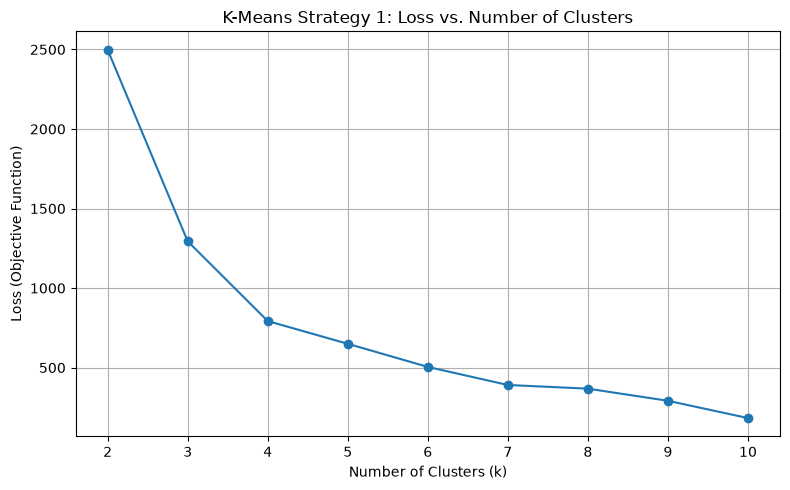

In [7]:
# Plot the final K-means loss for k = 2 through 10.
import matplotlib.pyplot as plt

k_values = list(range(2, 11))
loss_values = [losses[k] for k in k_values]

plt.figure(figsize=(8, 5))
plt.plot(k_values, loss_values, marker='o')
plt.xticks(k_values)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Loss (Objective Function)')
plt.title('K-Means Strategy 1: Loss vs. Number of Clusters')
plt.grid(True)
plt.tight_layout()
plt.show()

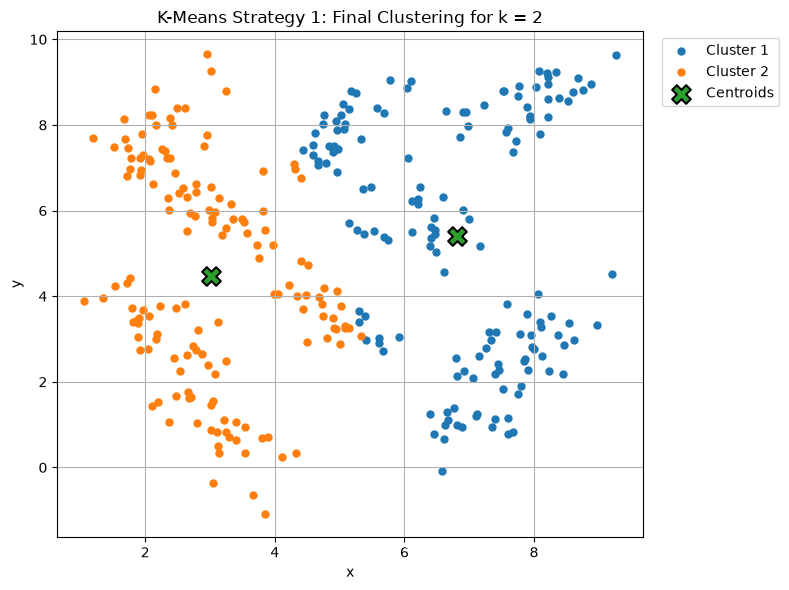

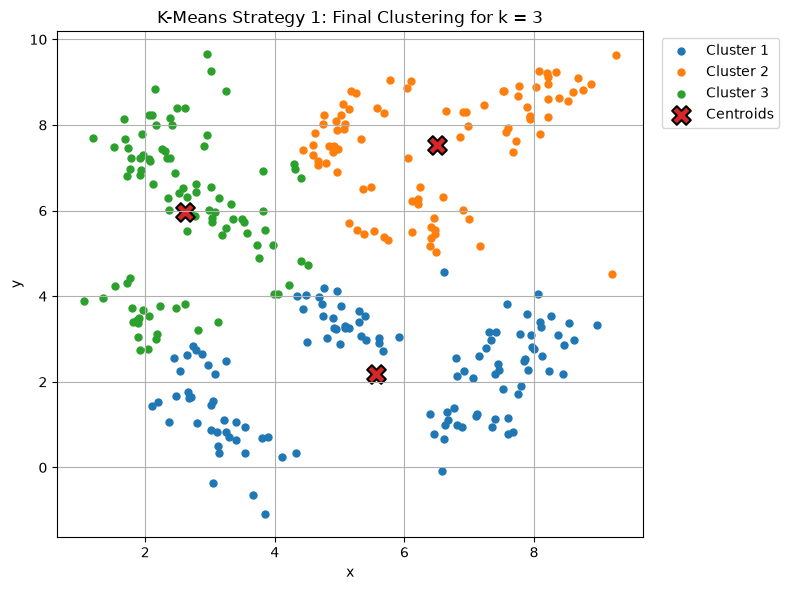

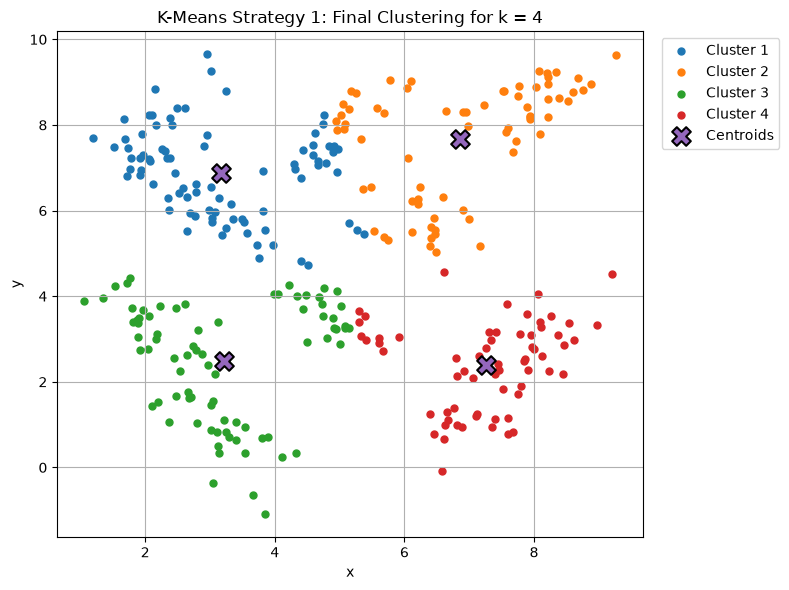

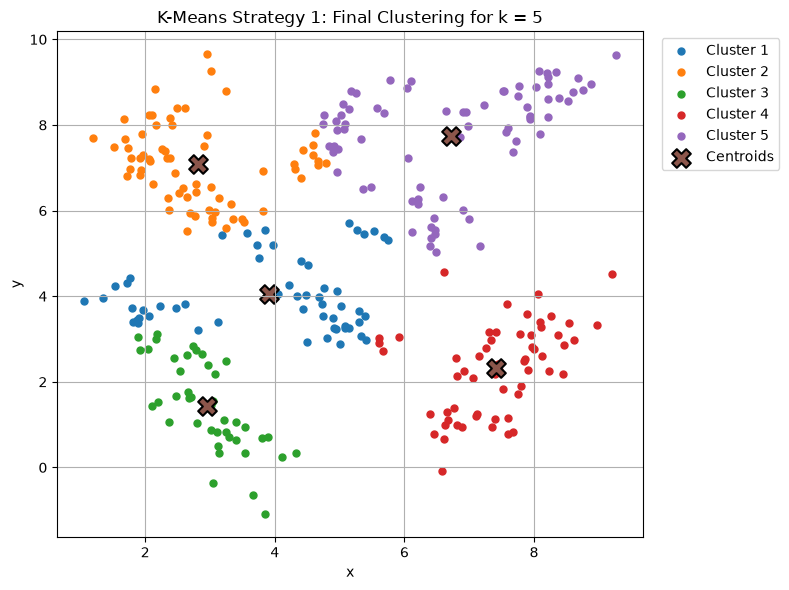

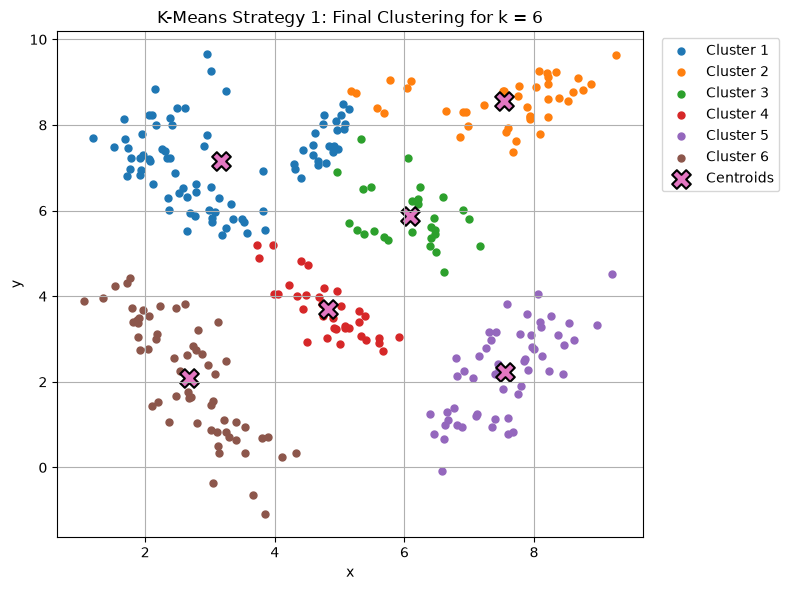

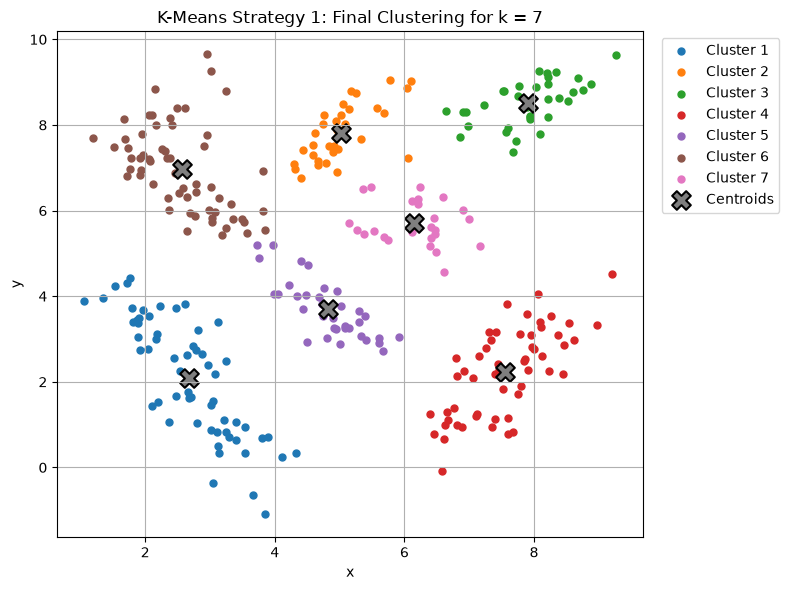

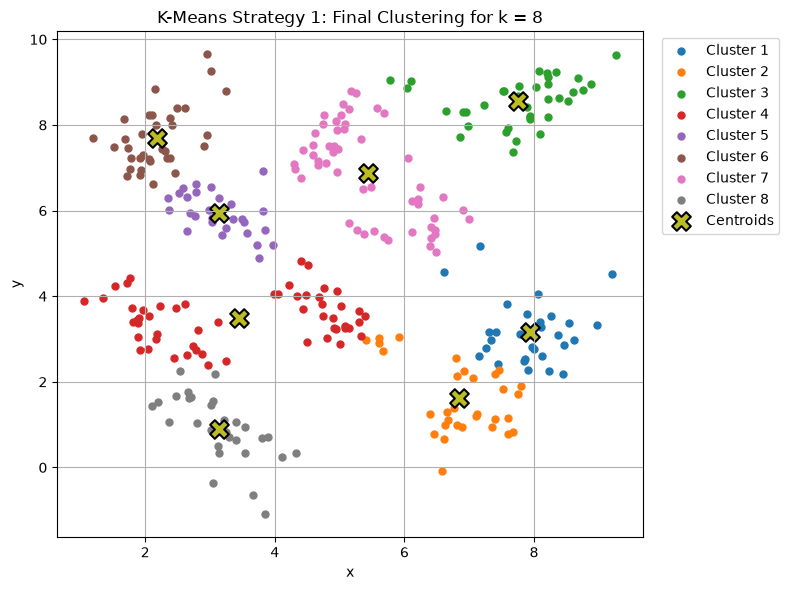

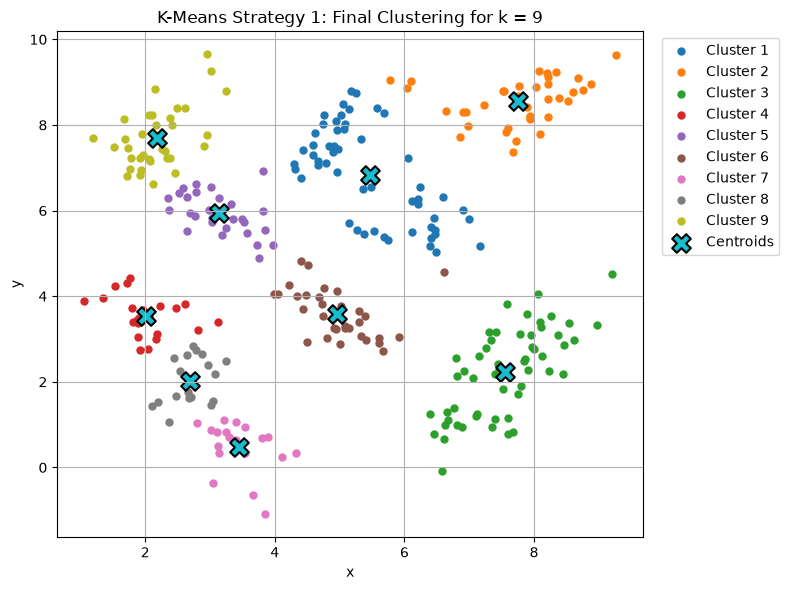

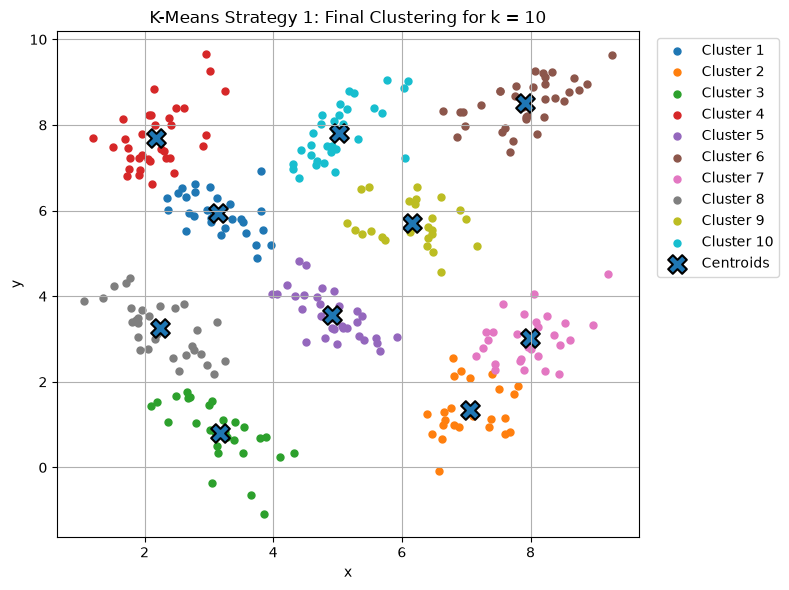

In [8]:
# Plot the final clustering and centroids for each value of k.
for k in range(2, 11):
    labels = final_labels[k]
    centroids = final_centroids[k]

    plt.figure(figsize=(8, 6))

    # Plot the points assigned to each cluster separately.
    for cluster_index in range(k):
        cluster_points = data[labels == cluster_index]

        plt.scatter(
            cluster_points[:, 0],
            cluster_points[:, 1],
            s=25,
            label=f'Cluster {cluster_index + 1}'
        )

    # Overlay the final cluster centroids.
    plt.scatter(
        centroids[:, 0],
        centroids[:, 1],
        marker='X',
        s=180,
        edgecolors='black',
        linewidths=1.5,
        label='Centroids'
    )

    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'K-Means Strategy 1: Final Clustering for k = {k}')
    plt.legend(
        bbox_to_anchor=(1.02, 1),
        loc='upper left'
    )
    plt.grid(True)
    plt.tight_layout()
    plt.show()